[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/toolkit/seaborn.ipynb)

# Seaborn: Statistical Charts

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Tell axes-level from figure-level seaborn functions and use each correctly.</li>
<li>Compare distributions of unequal groups honestly.</li>
<li>Read the bootstrap bands and boxes seaborn draws.</li>
<li>Draw a correlation heatmap with a sensible palette.</li>
</ul>
</div>

**Prerequisites:** <a href="../matplotlib/">Matplotlib: Figures, Axes and Honest Charts</a>. **Dataset:** Inside Airbnb (London). **Time:** about 40 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_airbnb, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", "{:,.2f}".format)

## The situation

Matplotlib gives you full control and makes you do everything yourself. **Seaborn** sits on top of it and adds what statisticians want most: it understands *tables of data*, splits a chart by a category with one argument (`hue=`), and computes summaries such as confidence intervals for you. The price of the convenience is knowing which of its two families of function you are calling.

We use the London Airbnb listings, tidied the way the pandas cleaning page showed (a numeric price, and a log of it).

In [2]:
import seaborn as sns

airbnb = load_airbnb()
df = airbnb.assign(price=pd.to_numeric(airbnb["price"].str.replace(r"[$,]", "", regex=True), errors="coerce"))
df = df[df["price"].notna() & df["room_type"].isin(["Entire home/apt", "Private room"])].copy()     # the two big room types, listings with a price
df["log_price"] = np.log10(df["price"])
top_areas = df["neighbourhood_cleansed"].value_counts().head(6).index
print(f"{len(df):,} listings with a price in the two main room types")

sns.set_theme(style="whitegrid", palette=[style.BLUE, style.ORANGE, style.GREEN, style.RED])      # the course's colourblind-safe colours
df[["room_type", "neighbourhood_cleansed", "accommodates", "bedrooms", "price"]].head(3)

59,606 listings with a price in the two main room types


,room_type,neighbourhood_cleansed,accommodates,bedrooms,price
0,Entire home/apt,Lambeth,5,1.00,267.50
1,Private room,Islington,1,1.00,127.00
2,Entire home/apt,Kensington and Chelsea,2,1.00,137.50


## 1. Two families of function

| Family | Examples | Draws on | Returns | Use it when |
|---|---|---|---|---|
| **Axes-level** | `histplot`, `boxplot`, `scatterplot`, `heatmap` | an `ax` you pass in (`ax=`) | that `Axes` | you want it as one panel in your own matplotlib layout |
| **Figure-level** | `displot`, `catplot`, `relplot`, `pairplot`, `jointplot` | its own whole figure | a grid object | you want automatic faceting by `col=` / `row=` |

The most common confusion is treating a figure-level function like an axes-level one: you cannot hand `catplot` an `ax=`, and it returns a grid, not an axes.

## 2. Distributions

`histplot` with `hue=` overlays one distribution per category. Two settings matter. **`stat="density"` with `common_norm=False`** compares *shapes* even when the groups have very different sizes (otherwise the big group swamps the small one). **`log_scale=True`** handles the skewed price.

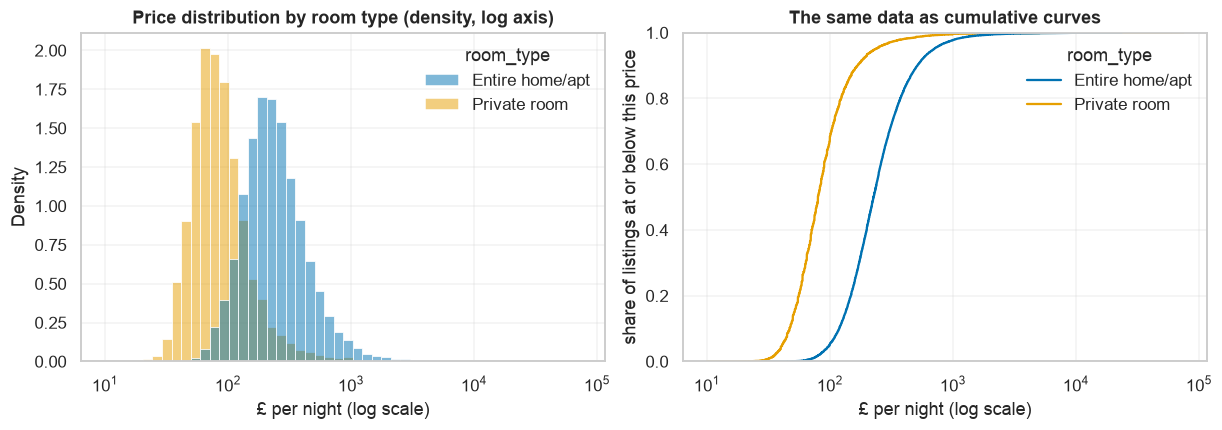

{'Entire home/apt': 227.0, 'Private room': 80.0}


In [3]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
sns.histplot(data=df, x="price", hue="room_type", stat="density", common_norm=False, log_scale=True, bins=50, ax=a)
a.set(title="Price distribution by room type (density, log axis)", xlabel="£ per night (log scale)")
sns.ecdfplot(data=df, x="price", hue="room_type", log_scale=True, ax=b)
b.set(title="The same data as cumulative curves", xlabel="£ per night (log scale)", ylabel="share of listings at or below this price")
plt.show()
print(df.groupby("room_type")["price"].median().round(0).to_dict())

**Reading the charts.** Entire homes (blue) cluster around £200 to £300 a night and private rooms (orange) around £80, with some overlap in the middle. Because both axes are log-scaled and each group is normalised to its own total, the *shapes* compare cleanly. The cumulative curves on the right make the gap unmistakable: the private-room curve sits to the left of the entire-home curve at every price, so at any given price a larger share of private rooms is at or below it. The medians, printed above, are £227 and £80.

## 3. Categories: boxes, bars and counts

A **box plot** shows the median (the line), the middle 50% (the box) and the spread, with the outliers as dots, for each category side by side.

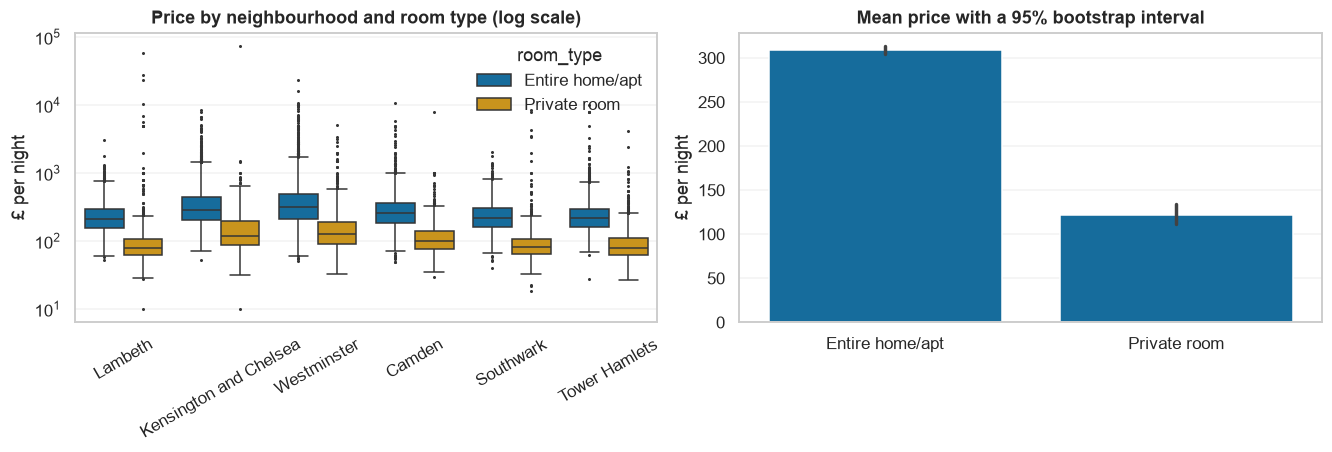

                  mean  median
room_type                     
Entire home/apt 309.00  227.00
Private room    122.00   80.00


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
sns.boxplot(data=df[df["neighbourhood_cleansed"].isin(top_areas)], x="neighbourhood_cleansed", y="price", hue="room_type", log_scale=True, ax=axes[0], fliersize=1)
axes[0].set(title="Price by neighbourhood and room type (log scale)", xlabel="", ylabel="£ per night"); axes[0].tick_params(axis="x", rotation=30)
sns.barplot(data=df, x="room_type", y="price", estimator="mean", errorbar=("ci", 95), ax=axes[1], color=style.BLUE)
axes[1].set(title="Mean price with a 95% bootstrap interval", xlabel="", ylabel="£ per night")
plt.show()
print(df.groupby("room_type")["price"].agg(["mean", "median"]).round(0).to_string())

**Reading the charts.** On the left, within every neighbourhood private rooms sit well below entire homes, and Kensington and Chelsea and Westminster are the priciest areas for both. The dots at the top are extreme listings: on a log axis a £70,000 private room is only a small step above a £10,000 one, which is both the benefit and the danger of a log scale.

On the right the bars show the **mean**, which is pulled well above the median by those expensive outliers: about £309 against a median of £227 for entire homes, and about £122 against £80 for private rooms. The thin black intervals say the means are estimated precisely, but a precisely estimated mean of a skewed variable is still a poor summary of a "typical" listing. Show the box plot alongside, or use the median.

## 4. Relationships

`lineplot` summarises y at each x and, by default, draws a **bootstrapped 95% confidence band** around the estimate: statistics you would otherwise code yourself. Here the median price at each size of property:

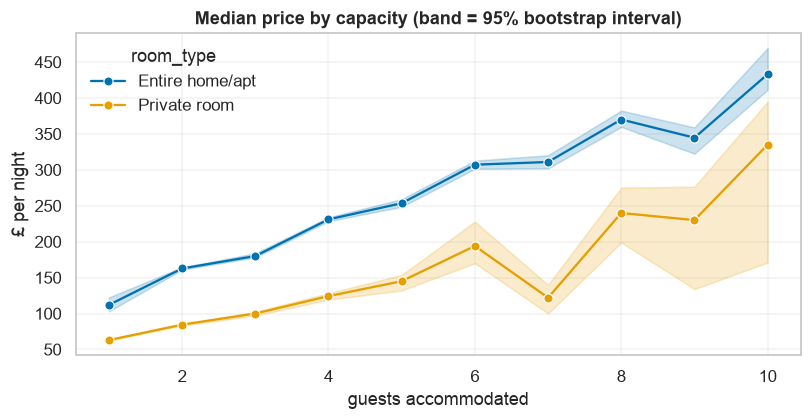

In [5]:
sized = df[df["accommodates"] <= 10]
fig, ax = plt.subplots(figsize=(8.5, 3.8))
sns.lineplot(data=sized, x="accommodates", y="price", hue="room_type", estimator="median", errorbar=("ci", 95), marker="o", ax=ax)
ax.set(title="Median price by capacity (band = 95% bootstrap interval)", xlabel="guests accommodated", ylabel="£ per night")
plt.show()

**Reading the chart.** Median price climbs steadily with the number of guests for both room types. The blue band is narrow because there are many entire homes of every size; the orange band is jumpy and wide beyond about six guests, because private rooms for large groups are rare and those medians rest on few listings (the same small-sample caution as on the pandas grouping page). The bands are doing their job: they show you *where not to over-read*.

## 5. Many variables at once: a correlation heatmap

`heatmap` draws a matrix as coloured cells. For a correlation matrix, use a **diverging palette centred on zero** so positive and negative read differently, and annotate the numbers. We use *rank* (Spearman) correlation, which is robust to the skew in price and reviews.

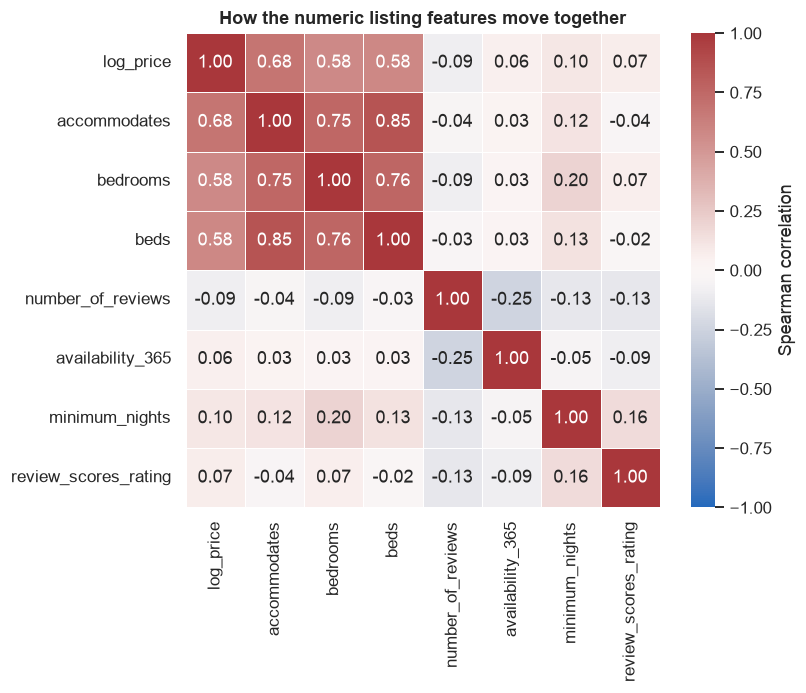

strongest links with log price: {'accommodates': 0.68, 'beds': 0.58, 'bedrooms': 0.58}


In [6]:
numeric = df[["log_price", "accommodates", "bedrooms", "beds", "number_of_reviews", "availability_365", "minimum_nights", "review_scores_rating"]]
corr = numeric.corr(method="spearman")

fig, ax = plt.subplots(figsize=(7.4, 5.6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, square=True, linewidths=0.5, cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.set(title="How the numeric listing features move together")
plt.show()
print("strongest links with log price:", corr["log_price"].drop("log_price").sort_values(key=abs, ascending=False).head(3).round(2).to_dict())

**Reading the heatmap.** Price (on the log scale) is most related to **size**: capacity (0.68), then bedrooms and beds (about 0.58). Reviews, availability and rating barely relate to price (all within about ±0.1). Notice the dark block at the top: capacity, bedrooms and beds are strongly related to *each other* (up to 0.85), so they carry overlapping information, which matters for regression (the same collinearity warning as on the NumPy and interpretation pages). One mild link elsewhere: listings with more reviews tend to have fewer available days (−0.25), plausibly because heavily booked listings have fewer free days, though a heatmap cannot show the cause.

## 6. Splitting a chart by a category: the figure-level functions

`displot`, `catplot` and `relplot` build a **grid of panels** from `col=` and `row=`. This is the seaborn idea that saves the most code: one call, one panel per neighbourhood.

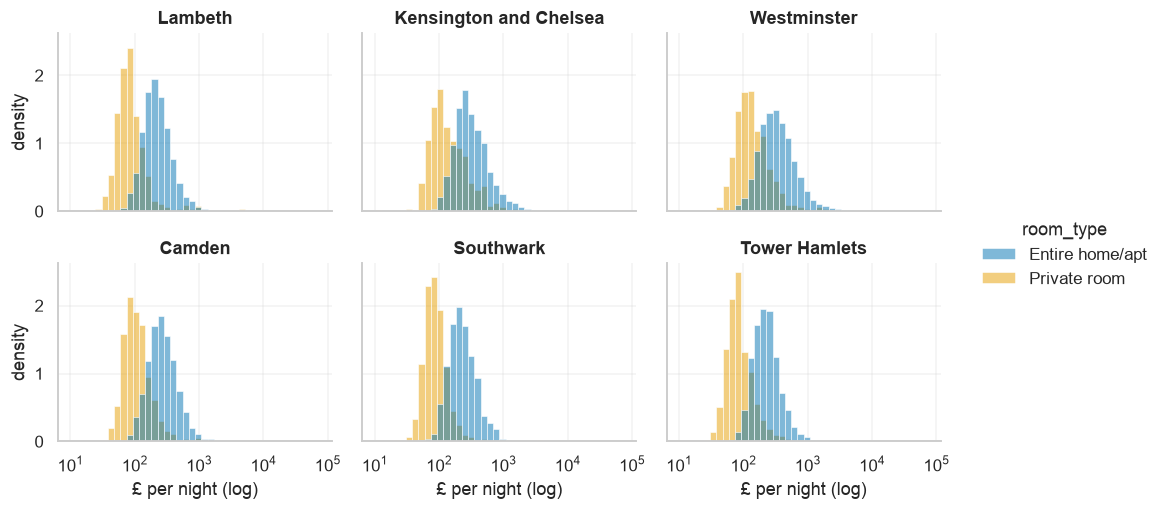

FacetGrid <- a figure-level function returns a grid, not an Axes


In [7]:
g = sns.displot(data=df[df["neighbourhood_cleansed"].isin(top_areas)], x="price", hue="room_type", col="neighbourhood_cleansed", col_wrap=3,
                log_scale=True, stat="density", common_norm=False, bins=40, height=2.4, aspect=1.25, facet_kws={"sharey": True})
g.set_titles("{col_name}"); g.set_axis_labels("£ per night (log)", "density")
plt.show()
print(type(g).__name__, "<- a figure-level function returns a grid, not an Axes")

**Reading the grid.** One call produced six panels. In every neighbourhood the orange private-room distribution sits to the left of the blue entire-home one, and the pair shifts right in Kensington and Chelsea and Westminster. Because we set `common_norm=False` each curve shows its own shape, and because the y-axes are shared the heights are comparable across panels. The returned grid object `g` lets you adjust titles and labels afterwards.

## Pitfalls at a glance

| Surprise | Cause | Fix |
|---|---|---|
| `TypeError` passing `ax=` to `catplot`/`displot` | figure-level functions own their figure | use the axes-level equivalent (`boxplot`, `histplot`) |
| Small groups vanish from a histogram | counts, not shapes, are drawn | `stat="density", common_norm=False` |
| A bar chart of the mean hides skew | one summary of a skewed variable | pair it with a box plot, or plot the median |
| Wide error bands appear from nowhere | the default 95% bootstrap interval | know it is there; `errorbar=None` to remove, or state what it is |
| Colours differ between charts | default palette | set one theme and palette once, at the top |
| `heatmap` colours mislead | sequential palette for signed data | a diverging palette with `center=0` |

## Check yourself

<details class="question">
<summary>1. Why does <code>histplot</code> need <code>stat="density", common_norm=False</code> to compare two room types?</summary>

Room types differ hugely in size (there are about twice as many entire homes as private rooms), so raw counts make the larger group look bigger everywhere. With `density` and `common_norm=False` each group is normalised to its *own* total, so the curves show shape and location rather than size.

</details>

<details class="question">
<summary>2. What is the difference between <code>sns.boxplot(...)</code> and <code>sns.catplot(kind="box", ...)</code>?</summary>

`boxplot` is **axes-level**: it draws on an `Axes` you give it (or the current one) and returns that axes, so it slots into your own `plt.subplots` layout. `catplot` is **figure-level**: it makes its own figure, can split into panels with `col=`/`row=`, and returns a grid object. Same chart, different level of control.

</details>

<details class="question">
<summary>3. The bar chart shows the mean price with a 95% interval. What does the interval mean, and what does it <em>not</em> tell you?</summary>

It is a bootstrap interval for the **mean**: roughly, the range the true mean plausibly lies in given this sample. It does *not* describe how much individual listings vary (that is the spread shown by the box plot), and it assumes the listings are an independent sample, which is questionable here since a few hosts own many listings.

</details>

## Exercises

<details class="question">
<summary>Draw the distribution of the number of reviews, split by room type. It is very skewed; which scale should you use, and what do you need to watch out for with zeros?</summary>

```python
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.histplot(data=df, x="number_of_reviews", hue="room_type", stat="density", common_norm=False, log_scale=True, bins=40, ax=ax)
```

A log axis suits the skew, but **zero cannot be placed on a log scale**, so listings with no reviews are dropped from the plot, **silently**. About one listing in five here (20%) has no reviews and would simply vanish. Either plot `np.log10(reviews + 1)` or say plainly that listings with zero reviews are not shown.

</details>

<details class="question">
<summary>Make a <code>catplot</code> of median price by <code>bedrooms</code> (0 to 5) faceted by room type, using a point plot.</summary>

```python
g = sns.catplot(data=df[df["bedrooms"].between(0, 5)], x="bedrooms", y="price", col="room_type", kind="point", estimator="median", errorbar=("ci", 95), height=3.4)
g.set_axis_labels("bedrooms", "median £ per night")
```

`kind="point"` joins the per-category summaries with a line, so you see the trend, and the vertical bars are the bootstrap intervals. Private rooms with several bedrooms are rare, so expect wide intervals there.

</details>

## Recap

- Seaborn understands tables: `hue=` splits by category, and it computes summaries and **bootstrap confidence intervals** for you.
- **Axes-level** functions (`histplot`, `boxplot`, `heatmap`) fit into your own subplots via `ax=`; **figure-level** ones (`displot`, `catplot`, `pairplot`) build their own faceted figure.
- For comparing groups of different size, use `stat="density", common_norm=False`; use a **log scale** for skewed money-like data.
- A box plot shows spread and outliers; a bar of means hides them. Use a **diverging palette with `center=0`** for signed matrices such as correlations.
- Set the theme and palette once, and keep charts colourblind-safe.

**Next:** scikit-learn, where these tables become models.